# Chapter 8

Python version of the R code for Chapter 8 of *In All Likelihood* (Pawitan, 2001).

Random numbers are generated with numpy, so simulated results will not
match the R output exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## Figure 8.1 (`FIG8-1.R`)

Variations of score functions.

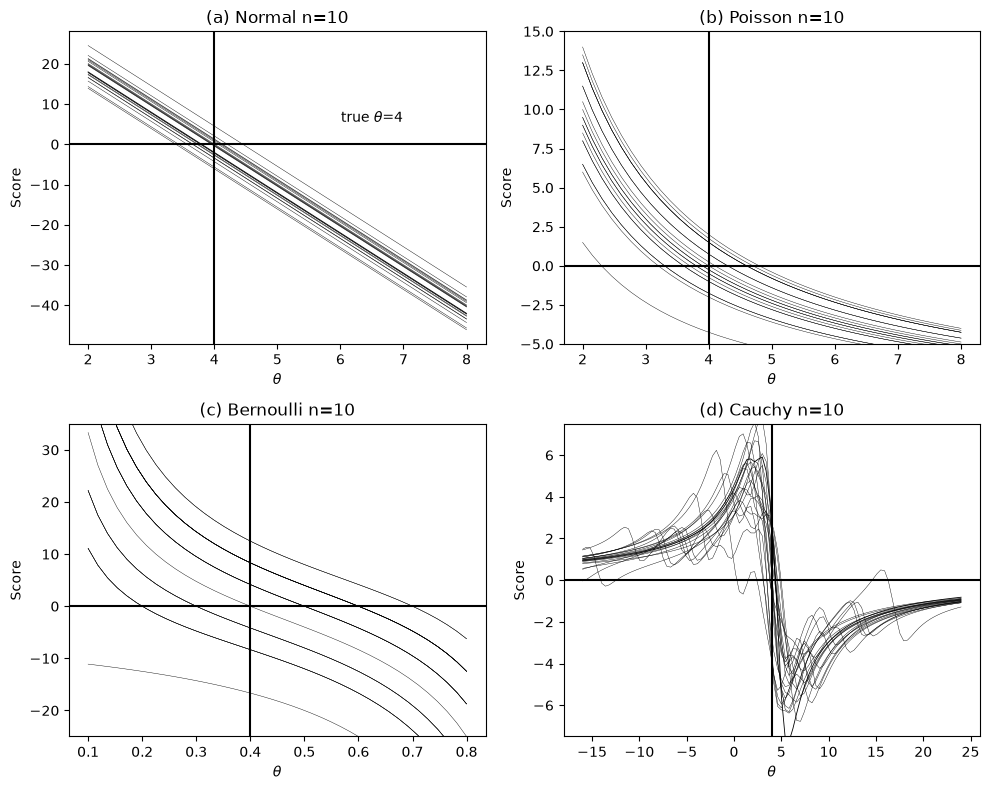

In [2]:
rng = np.random.default_rng(7)
n = 10

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

# ............................... normal:
t0 = 4
x = rng.normal(t0, size=n)
theta = np.linspace(t0 / 2, t0 * 2, 40)
stheta = n * (x.mean() - theta)

ax = axes[0]
ax.plot(theta, stheta, "k-", lw=0.6)
ax.text(6.5, 5.5, r"true $\theta$=4", ha="center")
ax.axvline(t0, color="k")
ax.axhline(0, color="k")
for i in range(20):
    x = rng.normal(t0, size=n)
    stheta = n * (x.mean() - theta)
    ax.plot(theta, stheta, "k-", lw=0.3)
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Score")
ax.set_title("(a) Normal n=10")

# ............................... Poisson:
t0 = 4
theta = np.linspace(t0 / 2, t0 * 2, 40)

ax = axes[1]
for i in range(20):
    x = rng.poisson(t0, size=n)
    stheta = -n + x.sum() / theta
    ax.plot(theta, stheta, "k-", lw=0.3)
ax.set_ylim(-5, 15)
ax.axvline(t0, color="k")
ax.axhline(0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Score")
ax.set_title("(b) Poisson n=10")

# ............................... Binomial
t0 = .4
theta = np.linspace(.1, .8, 40)

ax = axes[2]
for i in range(20):
    x = rng.binomial(n, t0)
    stheta = x / theta - (n - x) / (1 - theta)
    ax.plot(theta, stheta, "k-", lw=0.3)
ax.set_ylim(-25, 35)
ax.axvline(t0, color="k")
ax.axhline(0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Score")
ax.set_title("(c) Bernoulli n=10")


# ............................... Cauchy
def scauchy(x, mu):
    """Score function of the Cauchy location over mu +/- 20."""
    theta = mu + np.linspace(-20, 20, 100)
    score = np.array([np.sum(stats.cauchy.pdf(x, loc=t) * np.pi * 2 * (x - t))
                      for t in theta])
    return theta, score


n = 10
t0 = 4
x = rng.standard_cauchy(n) + t0
sx_theta, sx_score = scauchy(x, t0)

ax = axes[3]
ax.axhline(0, color="k")
ax.plot(sx_theta, sx_score, "k-", lw=0.6)
for i in range(20):
    x = rng.standard_cauchy(n) + t0
    sx_theta, sx_score = scauchy(x, t0)
    ax.plot(sx_theta, sx_score, "k-", lw=0.3)
ax.set_ylim(-7.5, 7.5)
ax.axvline(t0, color="k")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel("Score")
ax.set_title("(d) Cauchy n=10")

fig.tight_layout()
plt.show()